In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
DATA_FILE = Path('AB_NYC_2019.csv')
OUTPUT_DIR = Path('airbnb_project_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)


## Step 1: Exploratory Data Analysis (EDA) and Data Auditing

In [3]:
if not DATA_FILE.exists():
    raise FileNotFoundError('Place AB_NYC_2019.csv in the notebook working directory.')
df = pd.read_csv(DATA_FILE)
print('Shape:', df.shape)
display(df.head())
print('\nData types:\n', df.dtypes)
print('\nNumerical columns:', df.select_dtypes(include=np.number).columns.tolist())
print('\nCategorical columns:', df.select_dtypes(include=['object','category']).columns.tolist())
missing = pd.DataFrame({'missing_count': df.isna().sum(), 'missing_percent': (df.isna().mean()*100).round(2)})
display(missing[missing.missing_count > 0].sort_values('missing_percent', ascending=False))


Shape: (22059, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149.0,1.0,9.0,2018-10-19,0.21,6.0,365.0
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225.0,1.0,45.0,2019-05-21,0.38,2.0,355.0
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150.0,3.0,0.0,NaN,NaN,1.0,365.0
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89.0,1.0,270.0,2019-07-05,4.64,1.0,194.0
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80.0,10.0,9.0,2018-11-19,0.10,1.0,0.0



Data types:
 id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                             float64
minimum_nights                    float64
number_of_reviews                 float64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count    float64
availability_365                  float64
dtype: object

Numerical columns: ['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Categorical columns: ['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type', 'last_review']


,missing_count,missing_percent
last_review,3701,16.78
reviews_per_month,3701,16.78
name,15,0.07
host_name,14,0.06
room_type,1,0.00
price,1,0.00
number_of_reviews,1,0.00
minimum_nights,1,0.00
calculated_host_listings_count,1,0.00
availability_365,1,0.00


## Step 2: Data Cleaning and Handling Missing Values

In [5]:
data = df.copy()
# Missing reviews_per_month values are set to zero when there are no reviews.
if 'reviews_per_month' in data.columns:
    if 'number_of_reviews' in data.columns:
        no_reviews = data['number_of_reviews'].fillna(0).eq(0)
        print('Missing monthly-review values with zero reviews:', int((data['reviews_per_month'].isna() & no_reviews).sum()))
    data['reviews_per_month'] = data['reviews_per_month'].fillna(0)
# Drop last_review and irrelevant identifier/high-cardinality columns.
data = data.drop(columns=[c for c in ['last_review','id','name','host_id','host_name','neighbourhood'] if c in data.columns])
data = data.dropna(subset=['price'])
print('Shape after cleaning:', data.shape)


Missing monthly-review values with zero reviews: 3701
Shape after cleaning: (22058, 10)


## Step 3: Outlier Identification and Treatment

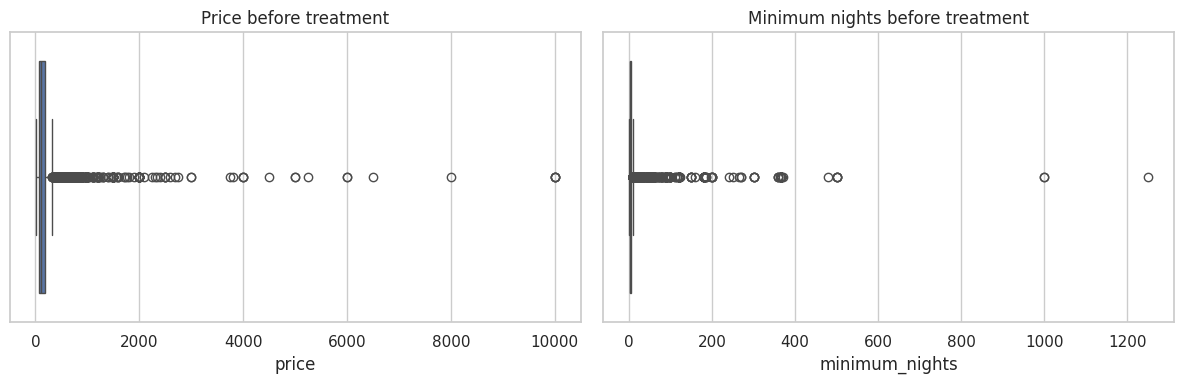

95th percentile price limit: 350.0
Rows removed: 1005
Shape after outlier treatment: (21053, 10)


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=data['price'], ax=axes[0]); axes[0].set_title('Price before treatment')
sns.boxplot(x=data['minimum_nights'], ax=axes[1]); axes[1].set_title('Minimum nights before treatment')
plt.tight_layout(); plt.show()
price_limit = data['price'].quantile(0.95)
before = len(data)
data = data[(data['price'] <= price_limit) & (data['minimum_nights'] < 365)]
print('95th percentile price limit:', price_limit)
print('Rows removed:', before - len(data))
print('Shape after outlier treatment:', data.shape)


## Step 4: Feature Selection and Categorical Encoding

In [7]:
# Drop neighbourhood because it has more than 200 unique values.
# One-hot encode neighbourhood_group and room_type, dropping the first category.
categorical_cols = [c for c in ['neighbourhood_group', 'room_type'] if c in data.columns]
model_data = pd.get_dummies(data.copy(), columns=categorical_cols, drop_first=True, dtype=int)
non_numeric = model_data.select_dtypes(exclude=np.number).columns.tolist()
model_data = model_data.drop(columns=non_numeric)
model_data = model_data.fillna(model_data.median(numeric_only=True))
X = model_data.drop(columns=['price'])
y = model_data['price']
print('X shape:', X.shape, '| y shape:', y.shape)
display(X.head())


X shape: (21053, 13) | y shape: (21053,)


,latitude,longitude,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,1.0,9.0,0.21,6.0,365.0,1,0,0,0,1,0
1,40.75362,-73.98377,1.0,45.0,0.38,2.0,355.0,0,1,0,0,0,0
2,40.80902,-73.94190,3.0,0.0,0.00,1.0,365.0,0,1,0,0,1,0
3,40.68514,-73.95976,1.0,270.0,4.64,1.0,194.0,1,0,0,0,0,0
4,40.79851,-73.94399,10.0,9.0,0.10,1.0,0.0,0,1,0,0,0,0


## Step 5: Feature-Target Separation and Validation Split

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print('Training set:', X_train.shape, y_train.shape)
print('Testing set:', X_test.shape, y_test.shape)


Training set: (16842, 13) (16842,)
Testing set: (4211, 13) (4211,)


## Step 6: Model Training and Evaluation

In [9]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print(f'R-squared (R²): {r2:.4f}')
print(f'Mean Absolute Error (MAE): ${mae:.2f}')
print(f'Mean Squared Error (MSE): {mse:.2f}')
print(f'Root Mean Squared Error (RMSE): ${rmse:.2f}')


R-squared (R²): 0.4754
Mean Absolute Error (MAE): $36.53
Mean Squared Error (MSE): 2445.38
Root Mean Squared Error (RMSE): $49.45


## Step 7: Residual Analysis and Interpretation

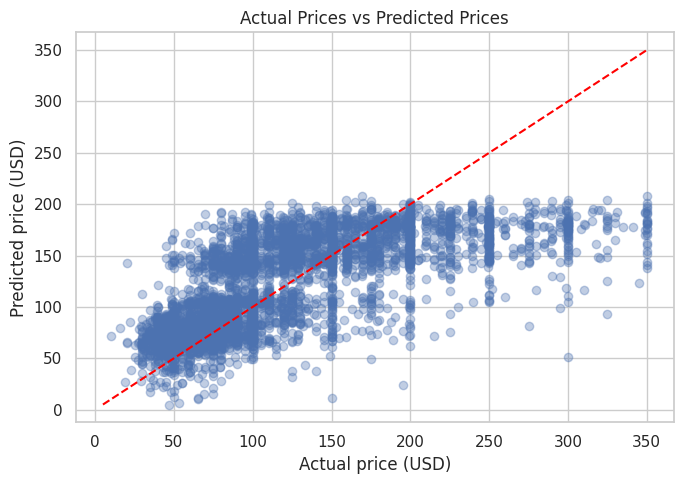

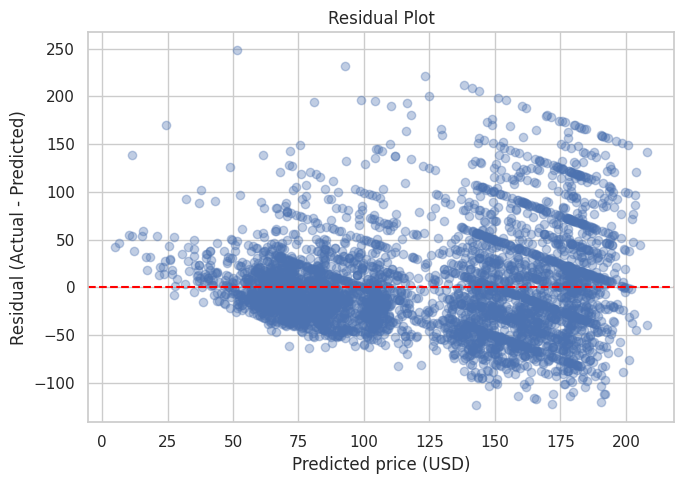

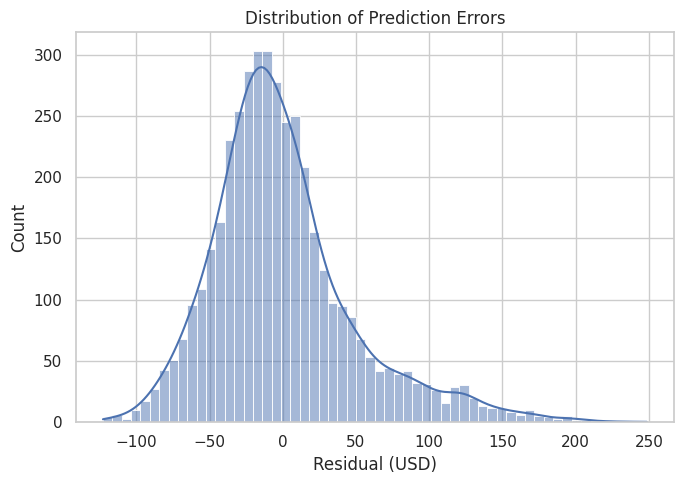

,Mean absolute error (USD)
price_group,
Higher-priced,44.531922
Lower-priced,28.707520


In [10]:
residuals = y_test - y_pred
low = min(float(y_test.min()), float(y_pred.min()))
high = max(float(y_test.max()), float(y_pred.max()))
plt.figure(figsize=(7,5)); plt.scatter(y_test, y_pred, alpha=0.35)
plt.plot([low, high], [low, high], '--', color='red')
plt.xlabel('Actual price (USD)'); plt.ylabel('Predicted price (USD)')
plt.title('Actual Prices vs Predicted Prices'); plt.tight_layout(); plt.show()
plt.figure(figsize=(7,5)); plt.scatter(y_pred, residuals, alpha=0.35)
plt.axhline(0, linestyle='--', color='red'); plt.xlabel('Predicted price (USD)')
plt.ylabel('Residual (Actual - Predicted)'); plt.title('Residual Plot'); plt.tight_layout(); plt.show()
plt.figure(figsize=(7,5)); sns.histplot(residuals, kde=True)
plt.xlabel('Residual (USD)'); plt.title('Distribution of Prediction Errors'); plt.tight_layout(); plt.show()
comparison = pd.DataFrame({'actual_price': y_test, 'predicted_price': y_pred})
comparison['absolute_error'] = (comparison.actual_price - comparison.predicted_price).abs()
median_price = comparison.actual_price.median()
comparison['price_group'] = np.where(comparison.actual_price <= median_price, 'Lower-priced', 'Higher-priced')
display(comparison.groupby('price_group').absolute_error.mean().rename('Mean absolute error (USD)'))
